# 01 — Pairwise Z-Score Backtest, Basket 1

Baseline-Run: `PairwiseZScoreStrategy` auf Basket 1 (liquideste Assets), Standard-Parameter, keine Basket-Overrides. Dient als Referenz, gegen die weitere Varianten (andere Baskets, `cluster_johansen`, andere Kostenannahmen) per `compare_runs` gemessen werden. Abgeleitet von `_template.ipynb` — siehe `README.md` für die Konvention.

In [27]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path("../..").resolve()))

import pandas as pd
from IPython.display import display

from src.data import load_ohlcv_panel, load_symbol_map
from src.backtest.cliques import CliqueTimeline
from src.backtest.config import BacktestConfig, BasketParams, split_calibration_backtest
from src.backtest.engine import BacktestEngine
from src.backtest import metrics as bt_metrics
from src.backtest import plots as bt_plots
from src.backtest import runs as bt_runs

print("Imports OK")

Imports OK


## 1. Run-Konfiguration

Der einzige Ort, den ein von diesem Template abgeleitetes Notebook üblicherweise ändert.

In [28]:
RUN_LABEL = "pairwise_basket1_baseline"
DESCRIPTION = (
    "Baseline: PairwiseZScoreStrategy, nur Basket 1, Standardparameter, "
    "keine Basket-Overrides."
)

DATA_START = pd.Timestamp("2024-07-23", tz="UTC")
DATA_END = pd.Timestamp("2026-07-22", tz="UTC")
BACKTEST_FRACTION = 0.2

BASKETS = ("Basket 1",)
CLIQUE_VARIANT = "raw"
STRATEGY_NAME = "pairwise_zscore"

INITIAL_CAPITAL = 100_000.0

In [29]:
DEFAULT_PARAMS = BasketParams(
    entry_z=3.0, exit_z=0.5, stop_z=10.0,
    formation_window_candles=288 * 7,
    max_candidate_pairs=3, pair_prefilter_top_n=15,
    min_half_life_candles=6, max_half_life_candles=288 * 2,
    max_concurrent_positions=3,
    fee_bps=10.0, slippage_bps=2.0,
)

BASKET_OVERRIDES: dict[str, dict] = {}  # Baseline -- keine Overrides

## 2. Daten laden

In [30]:
id_to_symbol, symbol_to_id = load_symbol_map()

# Panel muss VOR DATA_START genug Historie für formation_window_candles haben
# (Warm-up-Guard G7) -- hier grosszuegig ab DATA_START selbst geladen, da der
# Backtest ohnehin erst nach dem Calibration-Zeitraum beginnt (siehe Abschnitt 3).
panel = load_ohlcv_panel(start=DATA_START, end=DATA_END, fields=("open", "high", "low", "close"))
print(f"Panel: {panel['close'].shape[0]:,} Kerzen x {panel['close'].shape[1]} Symbole")

Panel: 209,953 Kerzen x 47 Symbole


In [31]:
timeline = CliqueTimeline.from_cache(
    variant=CLIQUE_VARIANT, id_to_symbol=id_to_symbol, baskets=list(BASKETS),
    start=DATA_START, end=DATA_END,
)
print(timeline.describe())

Discovery-Intervall (Median über Baskets): 1 days 00:00:00
  Basket 1: 503 Snapshots, 2024-07-30 00:00:00+00:00 → 2026-07-22 00:00:00+00:00, Intervall 1 days 00:00:00


## 3. Calibration/Backtest-Split & Look-Ahead-Checks

Der Backtest läuft **ausschließlich** auf dem Backtest-Zeitraum (letzte `BACKTEST_FRACTION` des verfügbaren Datenzeitraums) — derselbe Zeitraum, der auch in `02_tda_clustering`/`03_signal_generation` nicht für Kalibrierung angefasst wird.

In [32]:
CALIBRATION_RANGE, BACKTEST_RANGE = split_calibration_backtest(DATA_START, DATA_END, fraction=BACKTEST_FRACTION)
assert CALIBRATION_RANGE.end < BACKTEST_RANGE.start  # keine Ueberlappung, hart geprueft
print(f"Calibration: {CALIBRATION_RANGE.start.date()} -> {CALIBRATION_RANGE.end.date()}")
print(f"Backtest:    {BACKTEST_RANGE.start.date()} -> {BACKTEST_RANGE.end.date()}")

config = BacktestConfig(
    label=RUN_LABEL, description=DESCRIPTION,
    calibration_range=CALIBRATION_RANGE, backtest_range=BACKTEST_RANGE,
    baskets=BASKETS, clique_variant=CLIQUE_VARIANT, strategy_name=STRATEGY_NAME,
    default_params=DEFAULT_PARAMS, basket_overrides=BASKET_OVERRIDES,
    initial_capital=INITIAL_CAPITAL,
)

engine = BacktestEngine(config=config, panel=panel, timeline=timeline)
print()
print(engine.describe_guards())

Calibration: 2024-07-23 -> 2026-02-26
Backtest:    2026-02-27 -> 2026-07-22

G1 Clique-Verfügbarkeitslag: 1 days 00:00:00 (Discovery-Intervall: 1 days 00:00:00)
G2 PriceWindow-Cutoff: aktiv (Strategien können strukturell nicht über bar_index hinaus lesen)
G3 Ausführungs-Lag: 1 Kerze(n), Fill-Preis-Feld: open
G4 Eingefrorene Schätzer: SpreadDefinition wird bei Formation fixiert, kein Re-Fit während offener Position
G5 Basket-Zuordnung: aus dem Clique-Cache übernommen, nicht zur Bar-Zeit neu abgeleitet
G6 Calibration-Zeitraum: DateRange(start=Timestamp('2024-07-23 00:00:00+0000', tz='UTC'), end=Timestamp('2026-02-26 00:00:00+0000', tz='UTC'))  |  Backtest-Zeitraum: DateRange(start=Timestamp('2026-02-27 00:00:00+0000', tz='UTC'), end=Timestamp('2026-07-22 00:00:00+0000', tz='UTC'))
G7 Warm-up (Kerzen vor config.start, pro Basket): {'Basket 1': 2016}
G8 Snapshot-Ablauf (max_snapshot_age): auto


## 4. Backtest ausführen

In [33]:
if RUN_LABEL == "TEMPLATE_DO_NOT_RUN":
    raise SystemExit(
        "Dies ist die Kopiervorlage -- bitte zu einem neuen Notebook kopieren "
        "(cp _template.ipynb NN_kurzname.ipynb) und RUN_LABEL in Abschnitt 1 aendern, "
        "bevor der Backtest ausgefuehrt wird."
    )

import time
t0 = time.time()
result = engine.run(progress=True)
runtime_seconds = time.time() - t0
print(f"Laufzeit: {runtime_seconds:.1f}s | {len(result.trades)} Trades | Warnungen: {len(engine.warnings)}")

100%|██████████| 41761/41761 [00:09<00:00, 4347.46it/s]

Laufzeit: 9.7s | 80 Trades | Warnungen: 0


## 5. Metriken

In [34]:
BENCHMARK_SYMBOL = config.benchmark_symbol
benchmark_close = panel["close"][BENCHMARK_SYMBOL] if BENCHMARK_SYMBOL in panel["close"].columns else None

result.metrics = bt_metrics.compute_all_metrics(
    equity_curve=result.equity_curve, trades=result.trades,
    benchmark_close=benchmark_close, config=config,
)
result.metrics_by_basket = bt_metrics.metrics_by_basket(result.trades, config)
result.meta["runtime_seconds"] = runtime_seconds

display(result.summary())
display(result.metrics_by_basket)

total_return                                                                  -0.02975
cagr_bar                                                                     -0.073206
ann_volatility_bar                                                            0.017433
sharpe_bar                                                                   -4.352066
sortino_bar                                                                  -5.973694
calmar_bar                                                                   -2.194148
cagr_daily                                                                   -0.073206
ann_volatility_daily                                                          0.016155
sharpe_daily                                                                 -4.697229
sortino_daily                                                                -5.081325
calmar_daily                                                                 -2.241554
max_drawdown_pct                           

,n_trades,n_winners,n_losers,win_rate,profit_factor,expectancy,avg_win,avg_loss,payoff_ratio,largest_win,largest_loss,avg_holding_candles,avg_holding_hours,median_holding_hours,max_holding_hours,avg_return_on_notional,exit_reason_counts,pct_forced_exits
basket,,,,,,,,,,,,,,,,,,
Basket 1,80,21,59,0.2625,0.309475,-37.187076,63.490437,-73.021445,0.869477,182.286963,-368.18674,316.375,26.364583,18.416667,72.0,-0.00377,"{""stop"": 39, ""target"": 16, ""clique_break"": 14,...",0.0


## 6. Equity-Kurve & Drawdown

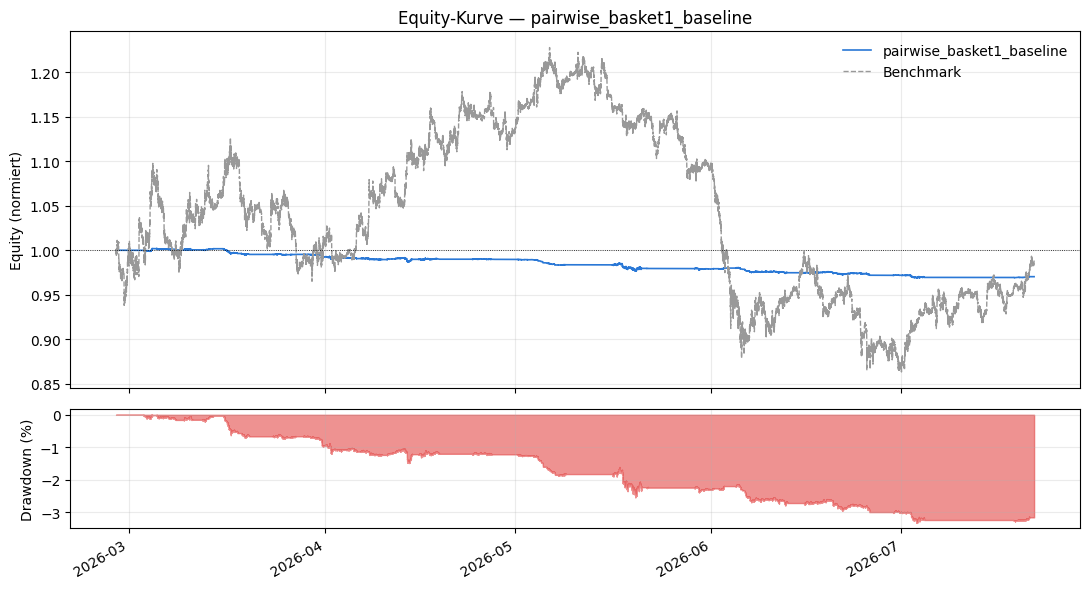

(<Figure size 1100x600 with 2 Axes>,
 (<Axes: title={'center': 'Equity-Kurve — pairwise_basket1_baseline'}, ylabel='Equity (normiert)'>,
  <Axes: ylabel='Drawdown (%)'>))

In [35]:
bt_plots.plot_equity_and_drawdown(result, benchmark_close=benchmark_close)

## 7. Trade-Analyse

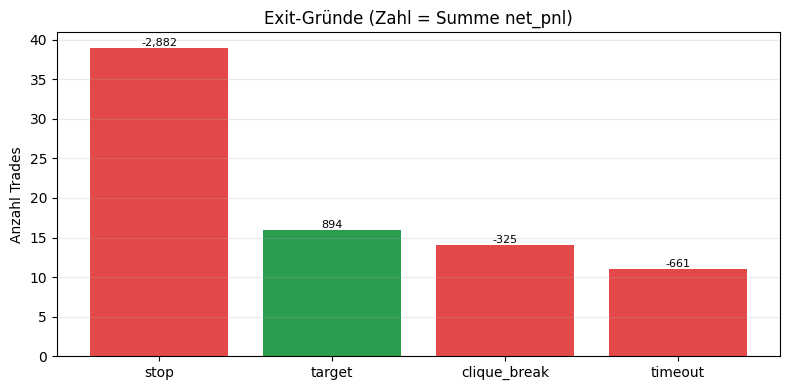

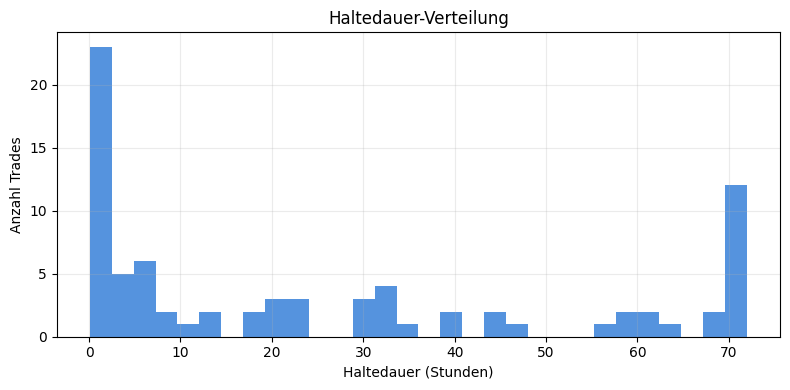

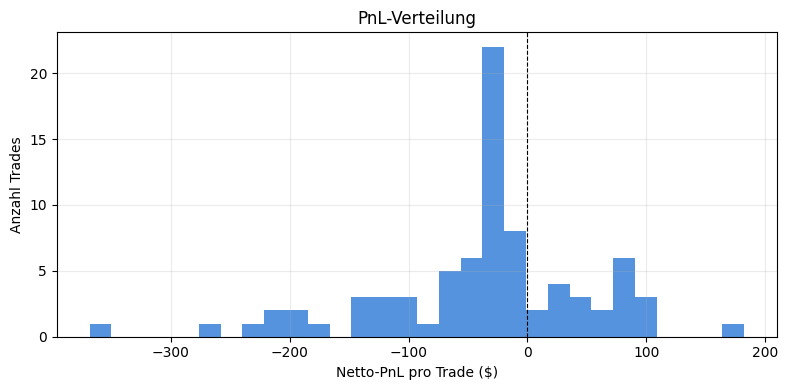

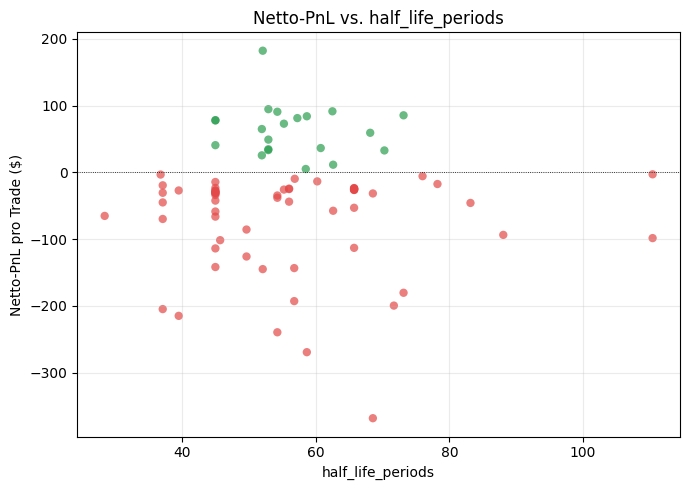

(<Figure size 700x500 with 1 Axes>,
 <Axes: title={'center': 'Netto-PnL vs. half_life_periods'}, xlabel='half_life_periods', ylabel='Netto-PnL pro Trade ($)'>)

In [36]:
bt_plots.plot_exit_reason_breakdown(result.trades)
bt_plots.plot_holding_period_histogram(result.trades)
bt_plots.plot_pnl_distribution(result.trades)
bt_plots.plot_pnl_vs_diagnostic(result.trades, "half_life_periods")

## 8. Run speichern

In [37]:
run_dir = bt_runs.save_run(result)
print(f"Gespeichert: {result.run_id}")
print(run_dir)

Gespeichert: 20260807-064911_pairwise-basket1-baseline_71656dbb
/Users/ryanmikus/Development/Python/00_Quant/26FS_BA/data/processed/backtests/20260807-064911_pairwise-basket1-baseline_71656dbb


## 9. Vergleich mit früheren Runs

In [38]:
display(bt_runs.list_runs(refresh_index=True).tail(10))

,run_id,created_at,label,description,strategy_name,clique_variant,baskets,backtest_start,backtest_end,fingerprint,n_trades,sharpe_daily,cagr_daily,max_drawdown_pct,runtime_seconds
0,20260807-064911_pairwise-basket1-baseline_7165...,2026-08-07T06:49:11.939619+00:00,pairwise_basket1_baseline,"Baseline: PairwiseZScoreStrategy, nur Basket 1...",pairwise_zscore,raw,[Basket 1],2026-02-27T00:00:00+00:00,2026-07-22T00:00:00+00:00,71656dbb,80,-4.697229,-0.073206,-0.033364,9.682648
1,20260807-064820_pairwise-basket1-baseline_4485...,2026-08-07T06:48:20.349560+00:00,pairwise_basket1_baseline,"Baseline: PairwiseZScoreStrategy, nur Basket 1...",pairwise_zscore,raw,[Basket 1],2026-02-27T00:00:00+00:00,2026-07-22T00:00:00+00:00,4485ad39,83,-4.210572,-0.058412,-0.027965,9.707830
2,20260807-064719_pairwise-basket1-baseline_027a...,2026-08-07T06:47:19.040262+00:00,pairwise_basket1_baseline,"Baseline: PairwiseZScoreStrategy, nur Basket 1...",pairwise_zscore,raw,[Basket 1],2026-02-27T00:00:00+00:00,2026-07-22T00:00:00+00:00,027a5782,249,-7.403749,-0.152574,-0.065734,11.075446
3,20260806-224014_pairwise-basket1-baseline_1bbd...,2026-08-06T22:40:14.730361+00:00,pairwise_basket1_baseline,"Baseline: PairwiseZScoreStrategy, nur Basket 1...",pairwise_zscore,raw,[Basket 1],2026-02-27T00:00:00+00:00,2026-07-22T00:00:00+00:00,1bbd202e,262,-8.697786,-0.157267,-0.067824,12.726509
4,20260806-223436_pairwise-basket1-baseline_1bbd...,2026-08-06T22:34:36.097772+00:00,pairwise_basket1_baseline,"Baseline: PairwiseZScoreStrategy, nur Basket 1...",pairwise_zscore,raw,[Basket 1],2026-02-27T00:00:00+00:00,2026-07-22T00:00:00+00:00,1bbd202e,262,-8.697786,-0.157267,-0.067824,9.086909


In [39]:
# Konkrete Runs zum Vergleich eintragen, z.B.:
# bt_runs.compare_runs([result.run_id, "<anderer-run-id>"])

## 10. Interpretation

_Wird nach dem ersten echten Lauf ausgefüllt: Exit-Reason-Verteilung, Beta vs. BTC, Kostenanteil am Bruttogewinn, Robustheit bei doppelten Kosten._